In [1]:
# =========================
# Standard libraries
# =========================
import os
import json
import random
import pickle
import warnings
import math
import re
from pathlib import Path

from datetime import datetime

warnings.filterwarnings("ignore")


# =========================
# Data processing
# =========================
import numpy as np
import pandas as pd
import geopandas as geopd


# =========================
# Geometry / GIS
# =========================
import shapely.wkt as wkt

from shapely.geometry import LineString, Polygon, Point

import mapclassify


# =========================
# Visualization
# =========================
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import matplotlib.colors as mcolors

from matplotlib import cm
from matplotlib.colors import (
    LinearSegmentedColormap,
    BoundaryNorm,
    Normalize,
)
from matplotlib.colorbar import ColorbarBase
from mpl_toolkits.axes_grid1 import make_axes_locatable



# =========================
# Display settings
# =========================
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": [
        "Times New Roman",   # Prefer if installed
        "Liberation Serif",  # Common on Ubuntu / Debian
        "Nimbus Roman",      # Common with TeX / Ghostscript
        "DejaVu Serif"       # Matplotlib fallback
    ],
    "mathtext.fontset": "stix",       # Math symbols closer to Times
    "axes.unicode_minus": False,
})

pd.set_option("display.max_columns", None)

In [2]:
df = pd.read_pickle('../../Data/e2018.pkl')
df.rename(columns={'BADGE':'badge'},inplace=True)
df.rename(columns={'DATE_RD':'date'},inplace=True)
df1 = pd.read_csv("../../Data/household_data/badge_location.csv")
df = pd.merge(df,df1[['badge','tractID','blockID']],on='badge',how='left')
df["date"] = pd.to_datetime(df["date"], errors="coerce")
df = df[df["date"].dt.month == 10]
df = df.dropna(subset=["blockID", "tractID"]).reset_index(drop=True)
df["blockID"] = df["blockID"].astype(int)
df["tractID"] = df["tractID"].astype(int)
df["blockID"] = df["blockID"].astype(str)
df["tractID"] = df["tractID"].astype(str)
df.index = range(df.shape[0])
df.head(2)

,badge,date,INT_VALUE_0000,INT_VALUE_0030,INT_VALUE_0100,INT_VALUE_0130,INT_VALUE_0200,INT_VALUE_0230,INT_VALUE_0300,INT_VALUE_0330,INT_VALUE_0400,INT_VALUE_0430,INT_VALUE_0500,INT_VALUE_0530,INT_VALUE_0600,INT_VALUE_0630,INT_VALUE_0700,INT_VALUE_0730,INT_VALUE_0800,INT_VALUE_0830,INT_VALUE_0900,INT_VALUE_0930,INT_VALUE_1000,INT_VALUE_1030,INT_VALUE_1100,INT_VALUE_1130,INT_VALUE_1200,INT_VALUE_1230,INT_VALUE_1300,INT_VALUE_1330,INT_VALUE_1400,INT_VALUE_1430,INT_VALUE_1500,INT_VALUE_1530,INT_VALUE_1600,INT_VALUE_1630,INT_VALUE_1700,INT_VALUE_1730,INT_VALUE_1800,INT_VALUE_1830,INT_VALUE_1900,INT_VALUE_1930,INT_VALUE_2000,INT_VALUE_2030,INT_VALUE_2100,INT_VALUE_2130,INT_VALUE_2200,INT_VALUE_2230,INT_VALUE_2300,INT_VALUE_2330,address,district,tractID,blockID
0,E162956,2018-10-01,0.47,0.48,0.46,0.39,0.51,0.57,0.45,0.36,0.44,0.44,0.44,0.41,0.43,0.41,0.39,0.63,0.41,0.47,0.51,0.68,0.60,0.65,0.70,0.83,1.02,0.87,0.82,0.88,0.88,0.91,0.89,1.07,1.26,1.26,1.15,1.07,0.90,0.88,0.87,0.86,0.64,0.59,0.76,0.62,0.70,0.58,0.46,0.54,46.0,POINT (-84.30334 30.388433),1801,18011011
1,E162956,2018-10-02,0.51,0.49,0.48,0.47,0.65,0.46,0.41,0.46,0.40,0.37,0.73,1.20,0.44,0.47,0.36,0.38,0.38,0.54,0.41,0.52,0.48,0.54,0.69,0.75,0.73,1.02,0.86,0.87,0.81,0.87,0.86,0.87,1.31,1.56,2.10,3.21,1.56,1.03,1.02,0.90,1.08,1.38,2.18,1.74,1.23,1.16,0.77,0.68,46.0,POINT (-84.30334 30.388433),1801,18011011


In [3]:
# 48 个半小时列（按时间排序）
value_cols = sorted(
    [c for c in df.columns if c.startswith("INT_VALUE_")],
    key=lambda c: int(c.split("_")[-1]),
)
assert len(value_cols) == 48

meta_cols = ["address", "district", "tractID", "blockID"]

# 日期统一到“天”
df["date"] = pd.to_datetime(df["date"], errors="coerce").dt.normalize()

# 同一天同一 badge 若有多条，先合并（按你业务选 sum / mean / first）
df = (
    df.groupby(["badge", "date"], as_index=False)[value_cols + meta_cols]
    .agg({**{c: "sum" for c in value_cols}, **{c: "first" for c in meta_cols}})
)

badges = np.sort(df["badge"].unique())

# 30 个日历日：按你的需求改起止日
day_range = pd.date_range("2018-10-01", periods=30, freq="D").normalize()
# 若要对齐整个 10 月（31 天），可改为：
# day_range = pd.date_range("2018-10-01", "2018-10-31", freq="D").normalize()

# 构造 badge × day 的完整网格
idx = pd.MultiIndex.from_product([badges, day_range], names=["badge", "date"])

df_full = (
    df.set_index(["badge", "date"])[value_cols + meta_cols]
    .reindex(idx)  # 缺的 (badge, day) 整行变成 NaN
)

# 数值列：NaN → 0（含“补出来的整天”）
df_full[value_cols] = (
    df_full[value_cols]
    .apply(pd.to_numeric, errors="coerce")
    .fillna(0.0)
)

# 元数据列：用每个 badge 的第一条非空记录向前填
df_full[meta_cols] = df_full.groupby(level=0)[meta_cols].transform(
    lambda s: s.ffill().bfill()
)

df = df_full.reset_index()
df.index = range(df.shape[0])

# 自检：每个 badge 恰好 30 天
assert df.groupby("badge").size().eq(len(day_range)).all()

In [4]:
value_cols = sorted(
    [c for c in df.columns if c.startswith("INT_VALUE_")],
    key=lambda c: int(c.split("_")[-1]),
)
n_slots = 30 * len(value_cols)  # 30 * 48 = 1440
# 每个 badge 在整月上的 0 占比
df_badge_zero = (
    df.groupby("badge")[value_cols]
    .apply(lambda g: (g == 0).to_numpy().sum() / (g.shape[0] * len(value_cols)))
    .reset_index(name="zero_ratio")
)


In [5]:
# 只保留 zero_ratio <= 0.25 的 badge
df_badge_zero = df_badge_zero[df_badge_zero["zero_ratio"] <= 0.25].reset_index(drop=True)
badges_keep = df_badge_zero["badge"]
df = df[df["badge"].isin(badges_keep)].reset_index(drop=True)
print(df['badge'].nunique())
df.head()

52162


,badge,date,INT_VALUE_0000,INT_VALUE_0030,INT_VALUE_0100,INT_VALUE_0130,INT_VALUE_0200,INT_VALUE_0230,INT_VALUE_0300,INT_VALUE_0330,INT_VALUE_0400,INT_VALUE_0430,INT_VALUE_0500,INT_VALUE_0530,INT_VALUE_0600,INT_VALUE_0630,INT_VALUE_0700,INT_VALUE_0730,INT_VALUE_0800,INT_VALUE_0830,INT_VALUE_0900,INT_VALUE_0930,INT_VALUE_1000,INT_VALUE_1030,INT_VALUE_1100,INT_VALUE_1130,INT_VALUE_1200,INT_VALUE_1230,INT_VALUE_1300,INT_VALUE_1330,INT_VALUE_1400,INT_VALUE_1430,INT_VALUE_1500,INT_VALUE_1530,INT_VALUE_1600,INT_VALUE_1630,INT_VALUE_1700,INT_VALUE_1730,INT_VALUE_1800,INT_VALUE_1830,INT_VALUE_1900,INT_VALUE_1930,INT_VALUE_2000,INT_VALUE_2030,INT_VALUE_2100,INT_VALUE_2130,INT_VALUE_2200,INT_VALUE_2230,INT_VALUE_2300,INT_VALUE_2330,address,district,tractID,blockID
0,E162956,2018-10-01,0.47,0.48,0.46,0.39,0.51,0.57,0.45,0.36,0.44,0.44,0.44,0.41,0.43,0.41,0.39,0.63,0.41,0.47,0.51,0.68,0.60,0.65,0.70,0.83,1.02,0.87,0.82,0.88,0.88,0.91,0.89,1.07,1.26,1.26,1.15,1.07,0.90,0.88,0.87,0.86,0.64,0.59,0.76,0.62,0.70,0.58,0.46,0.54,46.0,POINT (-84.30334 30.388433),1801,18011011
1,E162956,2018-10-02,0.51,0.49,0.48,0.47,0.65,0.46,0.41,0.46,0.40,0.37,0.73,1.20,0.44,0.47,0.36,0.38,0.38,0.54,0.41,0.52,0.48,0.54,0.69,0.75,0.73,1.02,0.86,0.87,0.81,0.87,0.86,0.87,1.31,1.56,2.10,3.21,1.56,1.03,1.02,0.90,1.08,1.38,2.18,1.74,1.23,1.16,0.77,0.68,46.0,POINT (-84.30334 30.388433),1801,18011011
2,E162956,2018-10-03,0.52,0.62,0.45,0.46,0.54,0.49,0.42,0.45,0.45,0.35,1.46,0.73,0.59,0.39,0.34,0.51,0.42,0.39,0.42,0.49,0.54,0.69,0.64,0.71,0.73,0.82,0.81,0.89,0.88,1.03,0.88,0.82,0.88,0.91,1.41,1.06,0.87,0.69,0.67,0.63,0.75,1.78,2.15,1.38,0.64,0.69,0.55,0.68,46.0,POINT (-84.30334 30.388433),1801,18011011
3,E162956,2018-10-04,0.50,0.49,0.57,0.50,0.46,0.55,0.45,0.42,0.43,0.53,0.96,0.96,0.51,0.38,0.51,0.38,0.37,0.39,0.51,0.41,0.49,0.54,0.61,0.68,0.97,0.88,0.88,0.87,0.83,0.88,0.89,1.03,0.88,0.83,0.88,0.95,0.89,0.93,0.75,0.66,0.83,1.33,0.93,0.58,0.62,0.47,0.48,2.13,46.0,POINT (-84.30334 30.388433),1801,18011011
4,E162956,2018-10-05,0.57,0.42,0.38,0.51,0.43,0.34,0.39,0.34,0.53,0.38,1.65,1.19,0.41,0.39,0.52,0.34,0.40,0.38,0.39,0.45,0.50,0.64,0.65,0.74,0.88,0.91,0.90,0.87,1.21,0.91,0.93,0.92,0.94,0.92,1.32,0.91,0.89,1.02,0.67,0.67,0.64,0.54,0.54,0.75,0.55,1.34,0.56,0.47,46.0,POINT (-84.30334 30.388433),1801,18011011


In [6]:
boundary_block = pd.read_csv('../../Data/boundary_data/tal_block_boundary.csv')
boundary_block["geometry"] = geopd.GeoSeries.from_wkt(boundary_block["geometry"])
boundary_block = geopd.GeoDataFrame(boundary_block, crs="EPSG:4326")
boundary_block["centroid"] = geopd.GeoSeries.from_wkt(boundary_block["centroid"])
boundary_block.index = range(boundary_block.shape[0])
boundary_block.head(2)

,tractID,blockID,geoID,geometry,centroid
0,2505,25054048,120730025054048,"POLYGON ((-84.21645 30.45289, -84.21638 30.452...",POINT (-84.21505 30.45322)
1,1801,18012017,120730018012017,"POLYGON ((-84.29834 30.39439, -84.29822 30.394...",POINT (-84.28963 30.39094)


In [7]:
boundary_tract = pd.read_csv('../../Data/boundary_data/tal_tract_boundary.csv')
boundary_tract["geometry"] = geopd.GeoSeries.from_wkt(boundary_tract["geometry"])
boundary_tract = geopd.GeoDataFrame(boundary_tract, crs="EPSG:4326")
boundary_tract["centroid"] = geopd.GeoSeries.from_wkt(boundary_tract["centroid"])
boundary_tract.head(2)

,tractID,geoID,geometry,centroid
0,200,12073000200,"POLYGON ((-84.28569 30.44135, -84.28569 30.441...",POINT (-84.27366 30.44473)
1,301,12073000301,"POLYGON ((-84.27816 30.43279, -84.27816 30.432...",POINT (-84.26941 30.42882)


In [8]:
def household_count_by_zone(df, id_col="blockID"):
    """
    id_col: 'blockID' 或 'tractID'
    返回每个区域的去重 badge 数量
    """
    meta = df.drop_duplicates(subset=["badge"])[["badge", "blockID", "tractID"]]
    meta[id_col] = meta[id_col].astype(str)
    cnt = (
        meta.groupby(id_col, as_index=False)["badge"]
        .nunique()
        .rename(columns={"badge": "n_household"})
    )
    return cnt

In [9]:
from matplotlib.colors import Normalize
from matplotlib.cm import ScalarMappable
def plot_household_heatmap_continuous(cnt_df, boundary_gdf, id_col="blockID", title=None, cmap="YlOrRd"):
    geo = geopd.GeoDataFrame(boundary_gdf.copy(), crs="EPSG:4326")
    geo[id_col] = geo[id_col].astype(str)
    geo = geo.merge(cnt_df, on=id_col, how="left")
    geo["n_household"] = geo["n_household"].fillna(0)
    vmin, vmax = 0, geo["n_household"].max()
    if vmax == vmin:
        vmax = vmin + 1
    norm = Normalize(vmin=vmin, vmax=vmax)
    fig, ax = plt.subplots(1, 1, figsize=(30, 18))
    geo.plot(
        ax=ax,
        column="n_household",
        cmap=cmap,           # 自带色带，如 "YlOrRd", "OrRd", "hot", "viridis"
        norm=norm,           # 连续映射；不要写 scheme / k
        legend=False,
        edgecolor="black",
        linewidth=0.4 if id_col == "blockID" else 0.8,
        missing_kwds={"color": "lightgrey"},
    )
    sm = ScalarMappable(cmap=cmap, norm=norm)
    sm.set_array([])
    cbar = fig.colorbar(sm, ax=ax, fraction=0.03, pad=0.02)
    cbar.set_label("Number of households")
    ax.set_title(title or f"Household heatmap by {id_col}")
    ax.set_axis_off()
    plt.tight_layout()
    plt.show()

In [10]:
def plot_household_count_curve(cnt_df, id_col="blockID", title=None):
    """各区域户数排序后的曲线（rank–count）"""
    y = np.sort(cnt_df["n_household"].to_numpy())
    x = np.arange(1, len(y) + 1)
    fig, ax = plt.subplots(figsize=(12, 5))
    ax.plot(x, y, color="#D62728", lw=2)
    ax.fill_between(x, y, alpha=0.15, color="#FFA500")
    ax.set_xlabel(f"Rank (sorted by household count per {id_col})")
    ax.set_ylabel("Number of households (unique badges)")
    ax.set_title(title or f"Household count distribution by {id_col}")
    ax.grid(True, alpha=0.3)
    plt.tight_layout()
    plt.show()
    # 可选：再看「户数」本身的直方图（有多少个 block 是 1 户、2 户…）
    fig, ax = plt.subplots(figsize=(8, 4))
    ax.hist(cnt_df["n_household"], bins=30, color="#FFA500", edgecolor="black", alpha=0.85)
    ax.set_xlabel(f"Households per {id_col}")
    ax.set_ylabel("Number of zones")
    ax.set_title(f"Histogram: households per {id_col}")
    plt.tight_layout()
    plt.show()

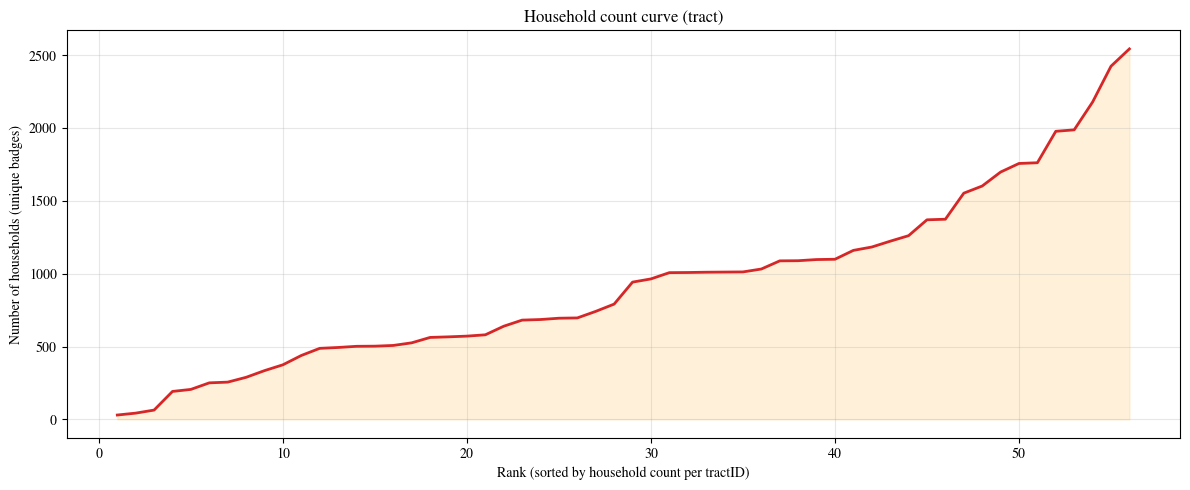

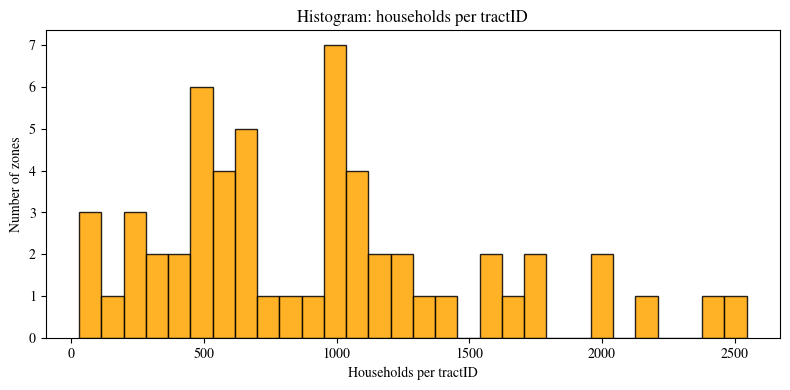

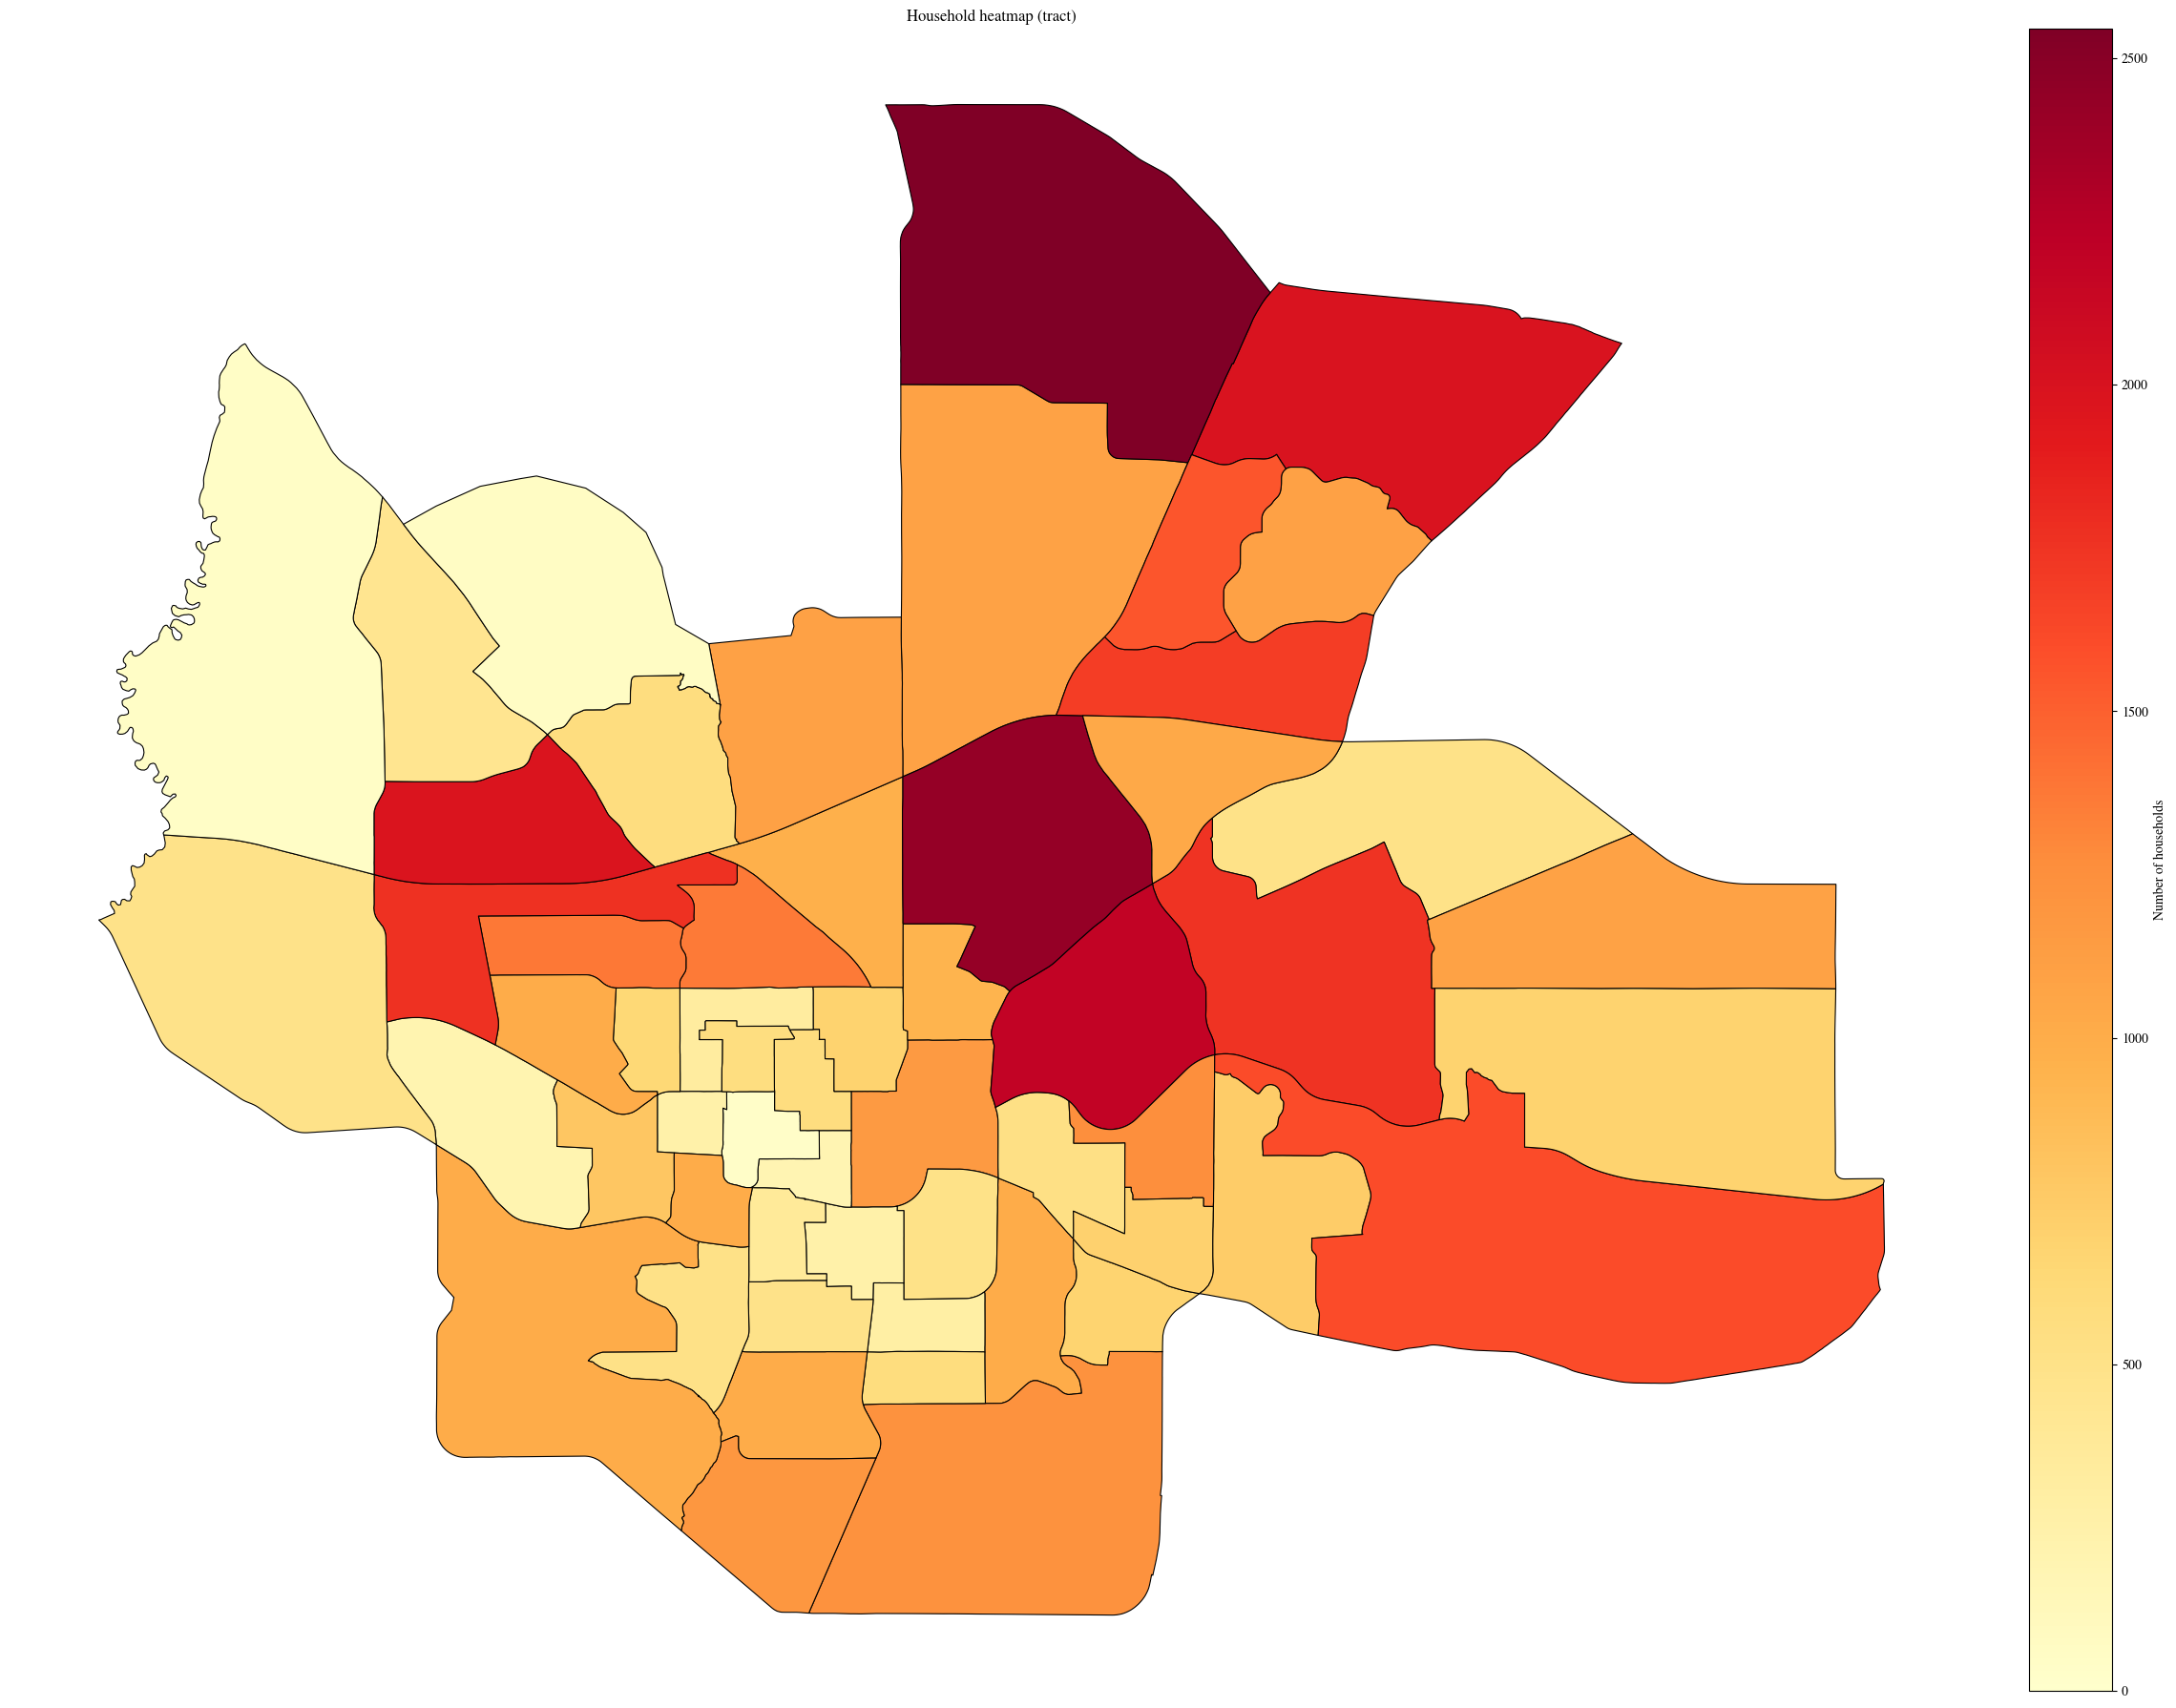

In [11]:
cnt_tract = household_count_by_zone(df, id_col="tractID")
plot_household_count_curve(cnt_tract, id_col="tractID",
    title="Household count curve (tract)")
geo_tract = plot_household_heatmap_continuous(
    cnt_tract,
    boundary_tract,
    id_col="tractID",
    title="Household heatmap (tract)",
)

In [12]:
id_cols = ["badge", "date", "address", "district", "tractID", "blockID"]

value_cols = [c for c in df.columns if c.startswith("INT_VALUE_")]
# 若 df 构造时保证列顺序就是 0000→2330，可不用再 sort；否则会乱序时按时间后缀排序更安全：
value_cols = sorted(value_cols)

assert len(value_cols) == 48, len(value_cols)

# 形状 (行数, 6 个四小时段, 每段 8 个半小时点) → 在最后一维求和 → (行数, 6)
arr_4h = df[value_cols].to_numpy(dtype="float64").reshape(len(df), 6, 8).sum(axis=2)

new_cols = [
    "INT_4h_1",  # 00:00–03:30
    "INT_4h_2",
    "INT_4h_3",
    "INT_4h_4",
    "INT_4h_5",
    "INT_4h_6",
]

df1 = pd.concat([df[id_cols].reset_index(drop=True), pd.DataFrame(arr_4h, columns=new_cols)], axis=1)

In [13]:
import pandas as pd
import numpy as np

value_cols = [f"INT_4h_{i}" for i in range(1, 7)]
meta_cols = ["address", "district", "tractID", "blockID"]

base = df1.copy()
base["day"] = pd.to_datetime(base["date"], errors="coerce").dt.normalize()

# （可选）同一天同一 badge 若有多条，先按业务规则聚合：这里用最常见的“求和”，你可改成 mean/first 等。
base = (
    base.groupby(["badge", "day"], as_index=False)[value_cols + meta_cols]
    .agg({**{c: "sum" for c in value_cols}, **{c: "first" for c in meta_cols}})
)

badges = np.sort(base["badge"].unique())

# 与前面 df 补齐的 30 天一致（2018-10-01 起）
day_range = pd.date_range("2018-10-01", periods=30, freq="D").normalize()

idx = pd.MultiIndex.from_product([badges, day_range], names=["badge", "day"])

wide06 = (
    base.set_index(["badge", "day"])[value_cols]
    .reindex(idx)
    .fillna(0)
)

# （可选自检）理论上每个 badge 正好 30 行 × 6 列 → 180
assert wide06.groupby(level=0).size().eq(30).all(), "badge-day 不完整，请检查 day_range"

# （badge，day）已按字典序：先 badge，再日期；对每个 badge，30 天的 6 列按行展开成 180
n_badge = badges.size
n_day = day_range.size
arr180 = wide06.to_numpy(dtype=float).reshape(n_badge, n_day * 6)

# 列名也可用 f"{day}_{k}"；这里给一个简单的 t000 ~ t179
col180 = [f"t{i:03d}" for i in range(180)]

meta = (
    base.sort_values(["badge", "day"])
        .drop_duplicates("badge")
        .set_index("badge")[meta_cols]
    .reindex(badges)  # 与 badges 对齐
)

df2 = pd.concat(
    [
        meta,
        pd.DataFrame(arr180, index=badges, columns=col180),
    ],
    axis=1,
).reset_index(names="badge")   # pandas>=2；若报错可改成 reset_index().rename(...)

In [14]:
value_cols_180 = [f"t{i:03d}" for i in range(180)]
badges_bad = (
    df2.groupby("badge")[value_cols_180]
    .max()
    .max(axis=1)  # 每个 badge 在 180 列上的最大值
    .pipe(lambda s: s[s > 100].index)
)
n_before = df2["badge"].nunique()
df2 = df2[~df2["badge"].isin(badges_bad)].reset_index(drop=True)
n_after = df2["badge"].nunique()
print(f"剔除任一 t* > 100 的户: {len(badges_bad)}")
print(f"badge 数: {n_before} -> {n_after}")

剔除任一 t* > 100 的户: 806
badge 数: 52162 -> 51356


In [16]:
import numpy as np
import pandas as pd

TARGET_N = 50000
RNG = np.random.default_rng(42)  # 可改种子


def allocate_tract_quotas(tract_counts: pd.Series, target_n: int = 10_000):
    N = tract_counts.astype(int)
    T = len(N)
    N_tot = int(N.sum())

    if N_tot < target_n:
        raise ValueError(f"可选总户数 {N_tot} < {target_n}")

    # 你要的平均：每 tract 配额 X = 10000 / tract 数（不是 N_tot/T）
    X = target_n / T

    small = N[N < X]   # 实际户数 < 配额线 → 全取
    large = N[N >= X]  # 实际户数 >= 配额线 → 分剩余

    s = pd.Series(0, index=N.index, dtype=int)
    s.loc[small.index] = small.astype(int)

    n_small_taken = int(s.sum())
    if n_small_taken >= target_n:
        raise ValueError(
            f"N_i < X 的 tract 全取已达 {n_small_taken} >= {target_n}。"
            f"此时 X={X:.2f}，请检查 tract 数 T={T} 或规则。"
        )

    R = target_n - n_small_taken
    L = len(large)
    if L == 0:
        raise ValueError("没有 N_i >= X 的 tract。")

    # 大 tract 均分 R（与之前相同的取整 + cap 逻辑）
    base = R / L
    s_large = pd.Series(base, index=large.index, dtype=float).clip(upper=large.astype(float))
    s_large_int = np.floor(s_large).astype(int)
    remainder = R - int(s_large_int.sum())
    frac = (s_large - s_large_int).sort_values(ascending=False)
    for tract_id in frac.index:
        if remainder <= 0:
            break
        if int(s_large_int.loc[tract_id]) < int(large.loc[tract_id]):
            s_large_int.loc[tract_id] += 1
            remainder -= 1
    while int(s_large_int.sum()) < R:
        for tract_id in large.index:
            if int(s_large_int.sum()) >= R:
                break
            if s_large_int.loc[tract_id] < large.loc[tract_id]:
                s_large_int.loc[tract_id] += 1
    while int(s_large_int.sum()) > R:
        for tract_id in s_large_int.sort_values(ascending=False).index:
            if int(s_large_int.sum()) <= R:
                break
            if s_large_int.loc[tract_id] > 0:
                s_large_int.loc[tract_id] -= 1

    s.loc[large.index] = s_large_int.astype(int)
    assert int(s.sum()) == target_n
    return s, X, R, L


def sample_badges_balanced_by_tract(
    df,
    target_n: int = TARGET_N,
    random_state: int = 42,
):
    """
    df: 含 badge, tractID；可多行/天，内部按 badge 去重
    返回: selected_badges (Series), quota (Series), info (dict)
    """
    rng = np.random.default_rng(random_state)

    meta = df.drop_duplicates(subset=["badge"])[["badge", "tractID"]].copy()
    meta["tractID"] = meta["tractID"].astype(str)

    tract_counts = meta.groupby("tractID")["badge"].nunique()
    quotas, X, R, L = allocate_tract_quotas(tract_counts, target_n=target_n)

    selected = []
    for tract_id, k in quotas.items():
        if k <= 0:
            continue
        pool = meta.loc[meta["tractID"] == tract_id, "badge"].values
        k = min(int(k), len(pool))
        chosen = rng.choice(pool, size=k, replace=False)
        selected.extend(chosen.tolist())

    selected_badges = pd.Series(selected, name="badge").drop_duplicates()
    if len(selected_badges) != target_n:
        raise RuntimeError(f"实际抽取 {len(selected_badges)} != {target_n}")

    info = {
        "X": X,
        "R": R,
        "L": L,
        "n_tracts": len(tract_counts),
        "N_tot": int(tract_counts.sum()),
        "n_small_tracts": int((tract_counts < X).sum()),
        "n_large_tracts": L,
        "quotas": quotas,
    }
    return selected_badges, quotas, info


# ---------- 使用 ----------
selected_badges, quotas, info = sample_badges_balanced_by_tract(df2, target_n=TARGET_N)
print(f"X (平均每 tract 户数) = {info['X']:.2f}")
print(f"小 tract 全取后剩余名额 R = {info['R']}")
print(f"大 tract 个数 L = {info['L']}")
print(f"已抽户数 = {len(selected_badges)}")
# 仅保留抽中的户（长表 df）
df_sampled = df2[df2["badge"].isin(selected_badges)].copy()

# 可选：导出 badge 列表
# selected_badges.to_csv("../../Data/household_data/sample_10k_badges.csv", index=False)

X (平均每 tract 户数) = 892.86
小 tract 全取后剩余名额 R = 37621
大 tract 个数 L = 28
已抽户数 = 50000


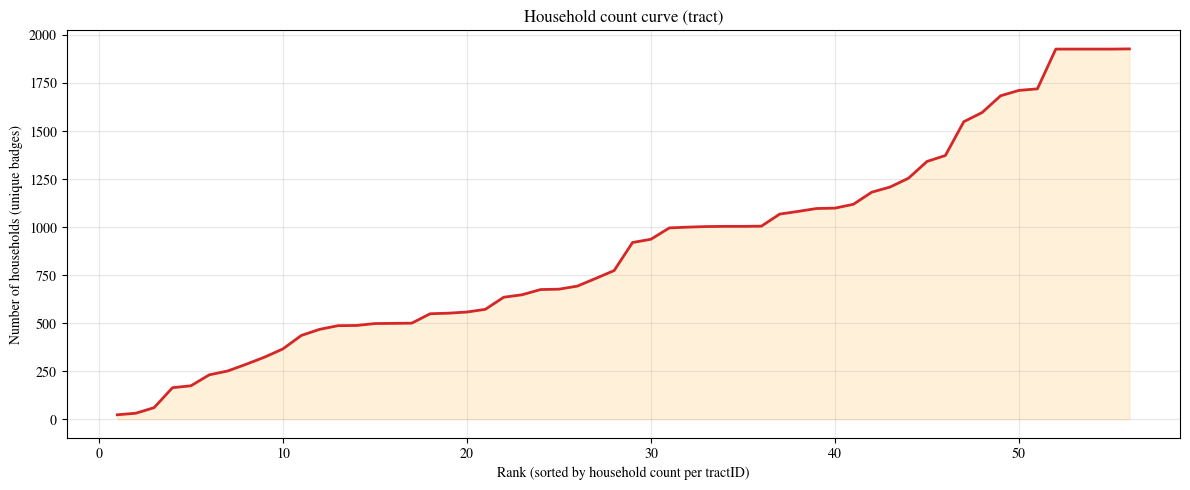

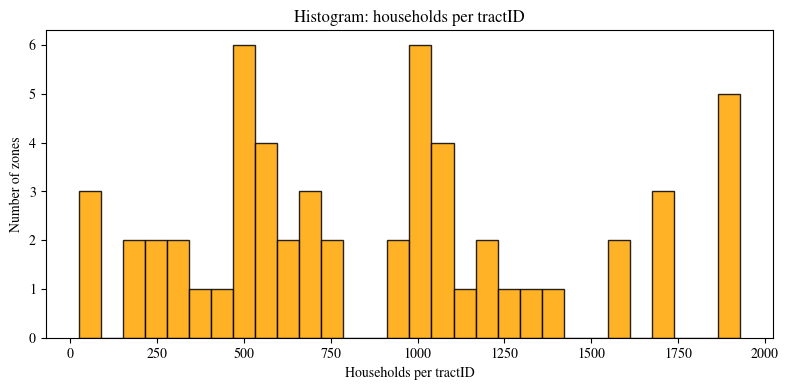

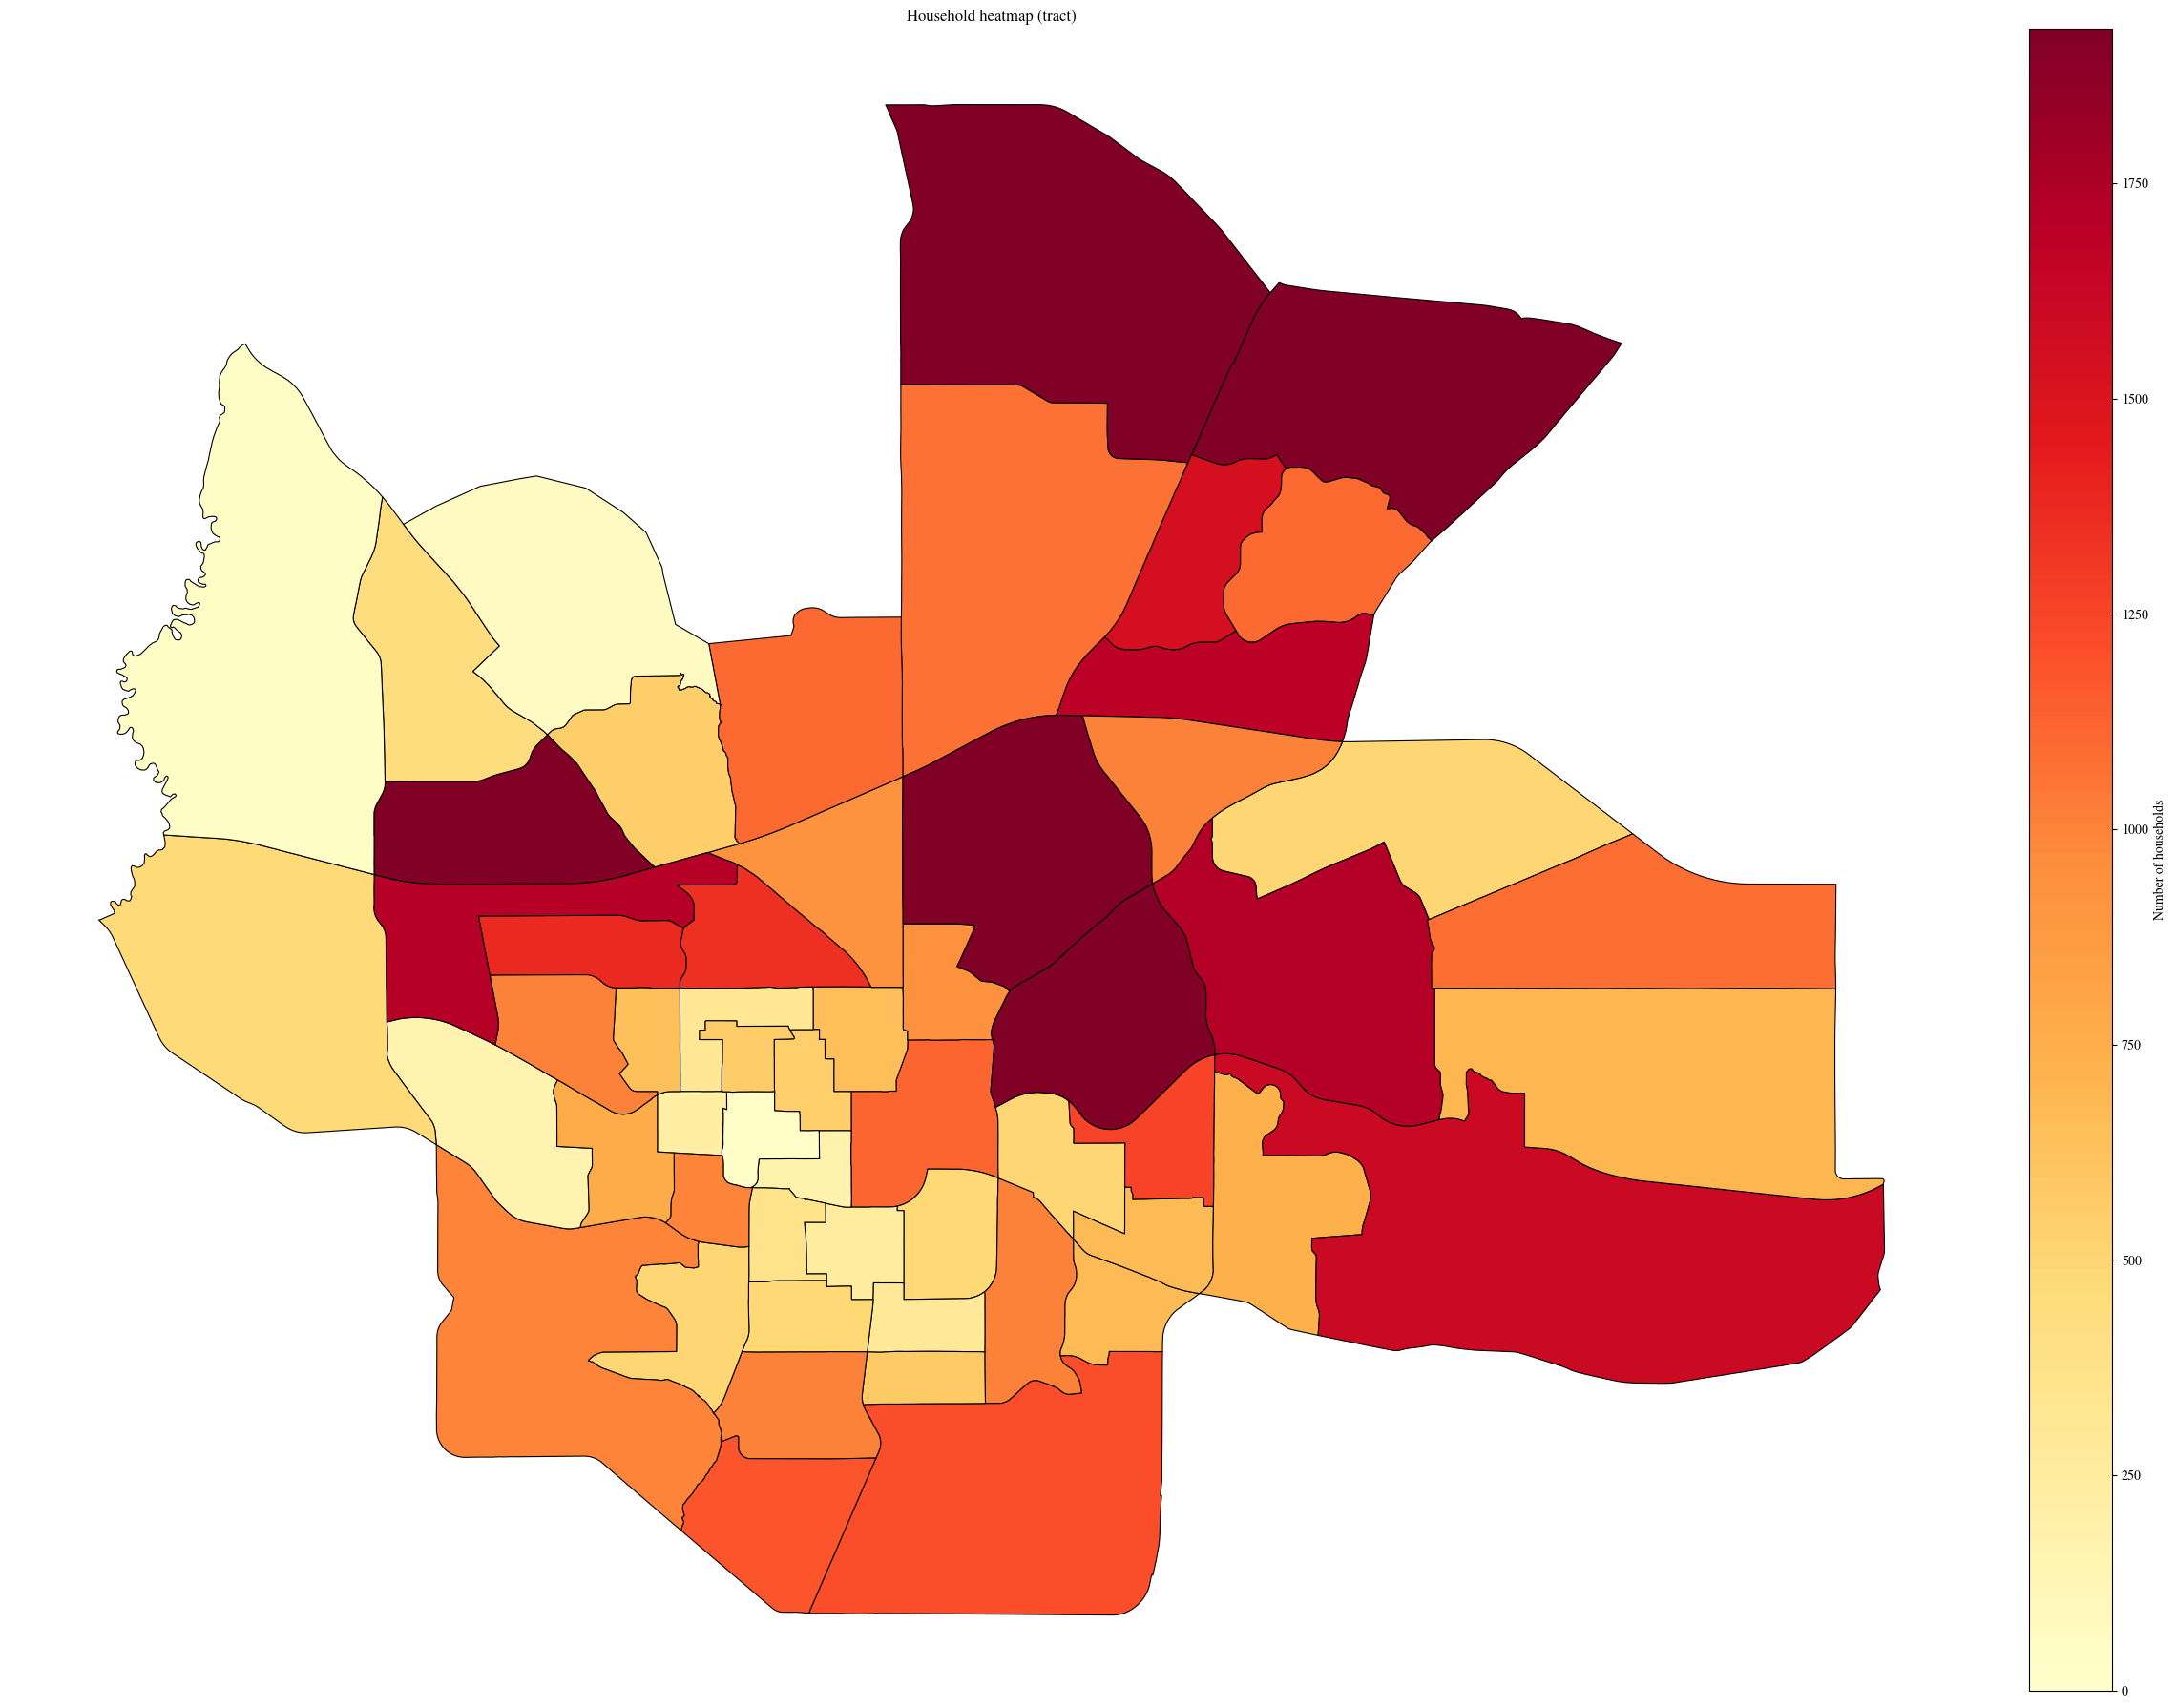

In [17]:
cnt_tract = household_count_by_zone(df_sampled, id_col="tractID")
plot_household_count_curve(cnt_tract, id_col="tractID",
    title="Household count curve (tract)")
geo_tract = plot_household_heatmap_continuous(
    cnt_tract,
    boundary_tract,
    id_col="tractID",
    title="Household heatmap (tract)",
)

In [18]:
TRACT_IDS = df['tractID'].unique().tolist()
sorted_ids = sorted(TRACT_IDS, key=int)
# 映射：原始 id -> 0..K-1
id_to_idx = {tid: i for i, tid in enumerate(sorted_ids)}
idx_to_id = {i: tid for tid, i in id_to_idx.items()}
K = len(sorted_ids)
# 保存（一个 json 就够）
MAP_PATH = Path("../Analysis/Result/tract_cond_mapper.json")  # 按你的路径改
MAP_PATH.parent.mkdir(parents=True, exist_ok=True)
with open(MAP_PATH, "w") as f:
    json.dump({"id_to_idx": id_to_idx, "K": K}, f, indent=2)

In [19]:
MAP_PATH = Path("../Analysis/Result/tract_cond_mapper.json")
with open(MAP_PATH) as f:
    meta = json.load(f)

id_to_idx = meta["id_to_idx"]
K = meta["K"]
def ids_to_cond(raw_ids):
    """
    raw_ids: 任意形状，str/int 原始 tractID
    返回: (N, 1, 1) int64，供 cond.npy 使用
    """
    flat = np.asarray(raw_ids).reshape(-1).astype(str)
    flat = np.char.strip(flat)
    out = np.array([id_to_idx[x] for x in flat], dtype=np.int64)
    return out.reshape(-1, 1, 1)

In [20]:
df_sampled.index = range(df_sampled.shape[0])
dfx = df_sampled[[f"t{i:03d}" for i in range(180)]]
dfc = df_sampled[["tractID"]]
X = dfx.to_numpy(dtype=float)
C = dfc.to_numpy(dtype=str)
X = np.expand_dims(X, axis=-1) 
C = np.expand_dims(C, axis=-1)
C = ids_to_cond(C)
print(X.shape)
print(C.shape)

(50000, 180, 1)
(50000, 1, 1)


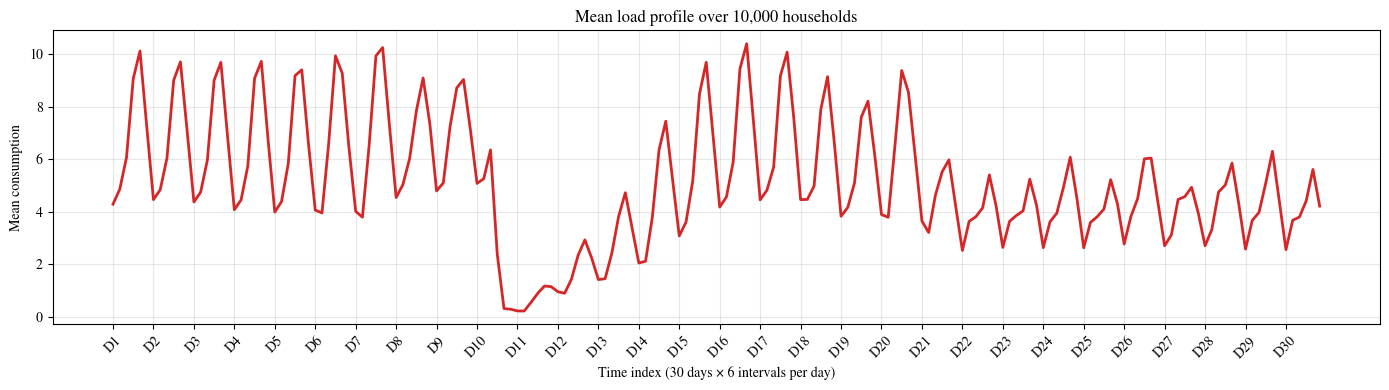

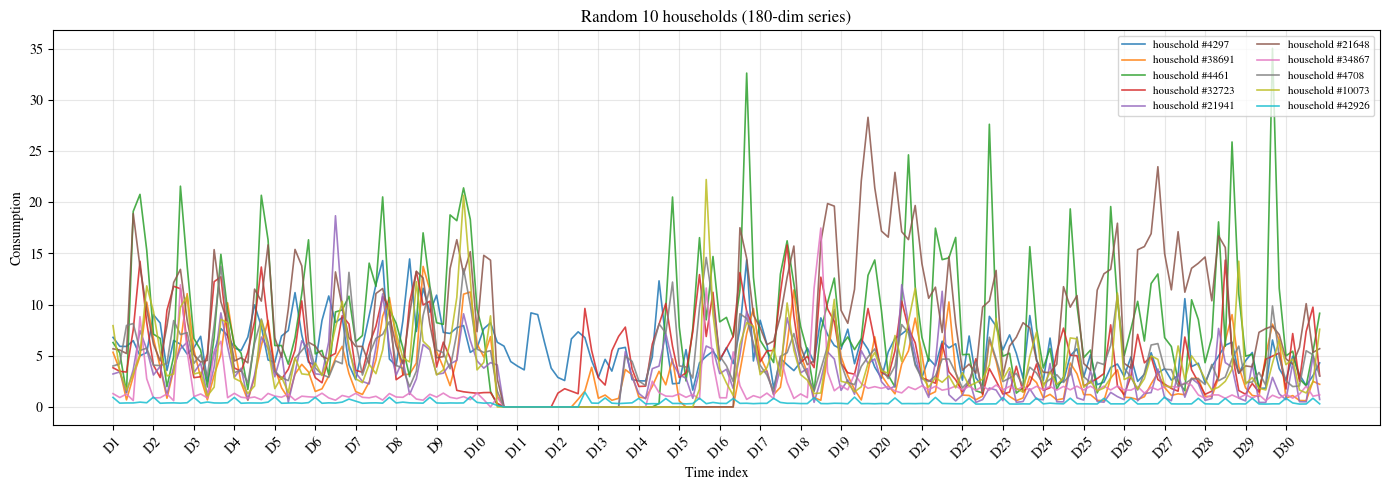

绘图范围 [0, 50]：8,979,589 个点；> 50 视为异常：20,411 (0.23%)


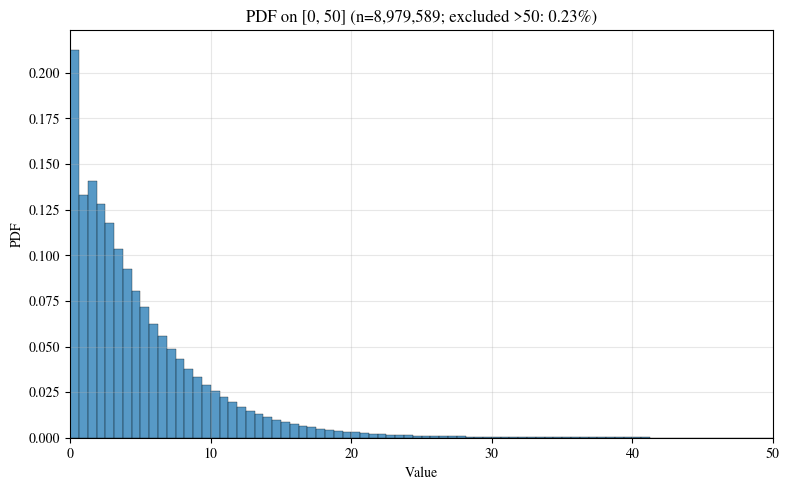

In [21]:
# X: (10000, 180, 1) — 30 天 × 6 个 4h 段
import matplotlib.pyplot as plt
import numpy as np

X2 = np.squeeze(X, axis=-1)  # (10000, 180)
n_day, n_seg = 30, 6
time_idx = np.arange(180)
day_ticks = np.arange(0, 180, n_seg)  # 每天起点
day_labels = [f"D{d+1}" for d in range(n_day)]

rng = np.random.default_rng(42)

# ---------- 图1：10000 户在 180 个时刻上的均值曲线 ----------
mean_curve = X2.mean(axis=0)

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(time_idx, mean_curve, color="#D62728", lw=2)
ax.set_xlabel("Time index (30 days × 6 intervals per day)")
ax.set_ylabel("Mean consumption")
ax.set_title("Mean load profile over 10,000 households")
ax.set_xticks(day_ticks)
ax.set_xticklabels(day_labels, rotation=45)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ---------- 图2：随机 10 户曲线 ----------
idx10 = rng.choice(X2.shape[0], size=10, replace=False)

fig, ax = plt.subplots(figsize=(14, 5))
for i, b in enumerate(idx10):
    ax.plot(time_idx, X2[b], lw=1.2, alpha=0.85, label=f"household #{b}")
ax.set_xlabel("Time index")
ax.set_ylabel("Consumption")
ax.set_title("Random 10 households (180-dim series)")
ax.set_xticks(day_ticks)
ax.set_xticklabels(day_labels, rotation=45)
ax.legend(loc="upper right", fontsize=8, ncol=2)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

# ---------- 图3：PDF（仅 0~50，>50 视为异常不纳入密度估计） ----------
vals_all = X2.ravel()
vmax = 50
vals = vals_all[(vals_all >= 0) & (vals_all <= vmax)]
n_out = (vals_all > vmax).sum()
pct_out = 100.0 * n_out / vals_all.size
print(f"绘图范围 [0, {vmax}]：{vals.size:,} 个点；> {vmax} 视为异常：{n_out:,} ({pct_out:.2f}%)")

fig, ax = plt.subplots(figsize=(8, 5))
ax.hist(
    vals,
    bins=80,
    range=(0, vmax),
    density=True,
    color="#1F77B4",
    alpha=0.75,
    edgecolor="black",
    linewidth=0.3,
)
ax.set_xlim(0, vmax)
ax.set_xlabel("Value")
ax.set_ylabel("PDF")
ax.set_title(f"PDF on [0, {vmax}] (n={vals.size:,}; excluded >{vmax}: {pct_out:.2f}%)")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [22]:
np.save('../SynEnergy/Data/Power/Tallahassee_seq_180_sample_50000.npy',X)
np.save('../SynEnergy/Data/Power/Tallahassee_seq_180_sample_50000_condition.npy',C)